<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan6/Latihan6MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import library

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.base import clone

pd.set_option("display.precision", 4)

## 2. Memuat dan mengenali dataset Wine

In [9]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Ukuran fitur (X):", X.shape)
print("Jumlah target (y):", y.shape[0])
print("Nama kelas:", list(wine.target_names))
print("\nJumlah sampel per kelas:")
print(y.value_counts().sort_index().rename(index=dict(enumerate(wine.target_names))))

X.head()

Ukuran fitur (X): (178, 13)
Jumlah target (y): 178
Nama kelas: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

Jumlah sampel per kelas:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Membagi data: 80% train dan 20% test

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Jumlah data train:", X_train.shape[0])
print("Jumlah data test :", X_test.shape[0])
print("\nProporsi kelas pada seluruh data:")
print(y.value_counts(normalize=True).sort_index().round(3))
print("\nProporsi kelas pada data train:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nProporsi kelas pada data test:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Jumlah data train: 142
Jumlah data test : 36

Proporsi kelas pada seluruh data:
target
0    0.331
1    0.399
2    0.270
Name: proportion, dtype: float64

Proporsi kelas pada data train:
target
0    0.331
1    0.401
2    0.268
Name: proportion, dtype: float64

Proporsi kelas pada data test:
target
0    0.333
1    0.389
2    0.278
Name: proportion, dtype: float64


## 4. Membuat model KNN dan Gaussian Naive Bayes

In [11]:
# StandardScaler dimasukkan ke dalam Pipeline agar scaler hanya di-fit pada data train.
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5, weights="distance")
)

gnb = GaussianNB()

models = {
    "KNN (k=5, distance)": knn,
    "Gaussian Naive Bayes": gnb
}

print("KNN menggunakan StandardScaler + KNeighborsClassifier.")
print("Gaussian Naive Bayes menggunakan GaussianNB.")

KNN menggunakan StandardScaler + KNeighborsClassifier.
Gaussian Naive Bayes menggunakan GaussianNB.


## 5. Melatih, mengukur waktu fit, dan mengukur waktu prediksi

In [12]:
# Waktu fit dirata-ratakan dari beberapa pengulangan agar pengukuran pada dataset kecil lebih stabil.
# Model untuk evaluasi akhir tetap di-fit pada seluruh data train.
FIT_REPEATS = 30
PREDICT_REPEATS = 100

results = []
trained_models = {}

for name, prototype in models.items():
    fit_durations = []
    for _ in range(FIT_REPEATS):
        model_copy = clone(prototype)
        start = time.perf_counter()
        model_copy.fit(X_train, y_train)
        fit_durations.append(time.perf_counter() - start)

    # Fit model final untuk menghasilkan prediksi evaluasi.
    final_model = clone(prototype)
    final_model.fit(X_train, y_train)
    trained_models[name] = final_model

    # Rata-rata waktu prediksi satu batch test.
    predict_durations = []
    for _ in range(PREDICT_REPEATS):
        start = time.perf_counter()
        _ = final_model.predict(X_test)
        predict_durations.append(time.perf_counter() - start)

    y_pred = final_model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Rata-rata waktu fit (ms)": np.mean(fit_durations) * 1000,
        "Rata-rata waktu prediksi per batch test (ms)": np.mean(predict_durations) * 1000
    })

comparison = pd.DataFrame(results).sort_values("Model").reset_index(drop=True)
comparison

,Model,Accuracy,Rata-rata waktu fit (ms),Rata-rata waktu prediksi per batch test (ms)
0,Gaussian Naive Bayes,0.9722,5.8822,3.2472
1,"KNN (k=5, distance)",0.9722,7.3552,7.8266


## 6. Interpretasi perbandingan model

In [13]:
# Tampilkan ringkasan berbasis hasil pengukuran aktual di runtime Colab.
best_accuracy_row = comparison.loc[comparison["Accuracy"].idxmax()]
fastest_fit_row = comparison.loc[comparison["Rata-rata waktu fit (ms)"].idxmin()]
fastest_predict_row = comparison.loc[comparison["Rata-rata waktu prediksi per batch test (ms)"].idxmin()]

print(f"Akurasi tertinggi pada split ini: {best_accuracy_row['Model']} "
      f"({best_accuracy_row['Accuracy']:.2%}).")
print(f"Waktu fit rata-rata paling singkat: {fastest_fit_row['Model']} "
      f"({fastest_fit_row['Rata-rata waktu fit (ms)']:.4f} ms).")
print(f"Waktu prediksi rata-rata paling singkat: {fastest_predict_row['Model']} "
      f"({fastest_predict_row['Rata-rata waktu prediksi per batch test (ms)']:.4f} ms per batch test).")

print("\nMengapa hasil dan biaya kedua model dapat berbeda?")
print("- KNN menentukan prediksi dari tetangga terdekat. Karena itu, skala fitur penting; "
      "StandardScaler digunakan sebelum menghitung jarak.")
print("- KNN menyimpan data latih dan menghitung kedekatan saat prediksi, sehingga biaya prediksi "
      "dapat lebih besar ketika jumlah data bertambah.")
print("- Gaussian Naive Bayes mempelajari statistik kelas saat fit dan menggunakan prior serta "
      "likelihood untuk prediksi. Model ini biasanya ringan, tetapi memakai asumsi distribusi "
      "Gaussian per fitur dalam setiap kelas.")
print("- Model dengan akurasi terbaik di satu pembagian data belum tentu selalu terbaik pada data lain. "
      "Waktu juga dapat berubah sesuai lingkungan eksekusi.")

Akurasi tertinggi pada split ini: Gaussian Naive Bayes (97.22%).
Waktu fit rata-rata paling singkat: Gaussian Naive Bayes (5.8822 ms).
Waktu prediksi rata-rata paling singkat: Gaussian Naive Bayes (3.2472 ms per batch test).

Mengapa hasil dan biaya kedua model dapat berbeda?
- KNN menentukan prediksi dari tetangga terdekat. Karena itu, skala fitur penting; StandardScaler digunakan sebelum menghitung jarak.
- KNN menyimpan data latih dan menghitung kedekatan saat prediksi, sehingga biaya prediksi dapat lebih besar ketika jumlah data bertambah.
- Gaussian Naive Bayes mempelajari statistik kelas saat fit dan menggunakan prior serta likelihood untuk prediksi. Model ini biasanya ringan, tetapi memakai asumsi distribusi Gaussian per fitur dalam setiap kelas.
- Model dengan akurasi terbaik di satu pembagian data belum tentu selalu terbaik pada data lain. Waktu juga dapat berubah sesuai lingkungan eksekusi.


## 7. Tambahan: uji `k=1` sampai `k=20` dengan cross-validation

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for k in range(1, 21):
    candidate = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k, weights="distance")
    )
    scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    cv_results.append({
        "k": k,
        "Rata-rata akurasi CV": scores.mean(),
        "Standar deviasi CV": scores.std()
    })

cv_table = pd.DataFrame(cv_results)
cv_table

,k,Rata-rata akurasi CV,Standar deviasi CV
0,1,0.9227,0.0335
1,2,0.9227,0.0335
2,3,0.9369,0.0254
3,4,0.9227,0.0131
4,5,0.9507,0.0353
5,6,0.9436,0.0354
6,7,0.9579,0.0405
7,8,0.9507,0.0353
8,9,0.9507,0.0353
9,10,0.9507,0.0353


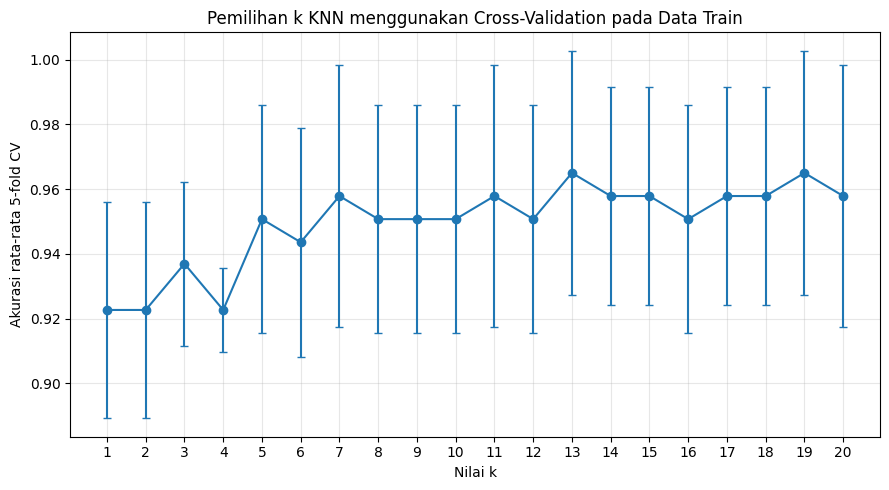

Nilai k terbaik berdasarkan rata-rata CV: 13
Akurasi CV rata-rata: 96.50%


In [15]:
plt.figure(figsize=(9, 5))
plt.errorbar(
    cv_table["k"],
    cv_table["Rata-rata akurasi CV"],
    yerr=cv_table["Standar deviasi CV"],
    marker="o",
    capsize=3
)
plt.xticks(range(1, 21))
plt.xlabel("Nilai k")
plt.ylabel("Akurasi rata-rata 5-fold CV")
plt.title("Pemilihan k KNN menggunakan Cross-Validation pada Data Train")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_idx = cv_table["Rata-rata akurasi CV"].idxmax()
best_k = int(cv_table.loc[best_idx, "k"])
best_cv_accuracy = float(cv_table.loc[best_idx, "Rata-rata akurasi CV"])
print(f"Nilai k terbaik berdasarkan rata-rata CV: {best_k}")
print(f"Akurasi CV rata-rata: {best_cv_accuracy:.2%}")

## 8. Evaluasi akhir KNN dengan k terbaik dari cross-validation

In [16]:
# Setelah k dipilih hanya dari data train, model dilatih pada seluruh data train
# dan dievaluasi satu kali pada test set.
tuned_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k, weights="distance")
)
tuned_knn.fit(X_train, y_train)
tuned_pred = tuned_knn.predict(X_test)
tuned_test_accuracy = accuracy_score(y_test, tuned_pred)

print(f"KNN dengan k terbaik ({best_k}) - akurasi test: {tuned_test_accuracy:.2%}")
print("Catatan: test set tidak digunakan untuk memilih k; pemilihan k dilakukan melalui CV pada data train.")

KNN dengan k terbaik (13) - akurasi test: 100.00%
Catatan: test set tidak digunakan untuk memilih k; pemilihan k dilakukan melalui CV pada data train.
